# REATAIL SALES EXPLORATORY DATA ANALYSIS (EDA)

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import matplotlib.ticker as mtick
%matplotlib inline 

In [3]:
df = pd.read_csv('retail_sales_eda.csv')
df.head(10)

,order_id,line_number,order_date,store_id,store_region,customer_id,customer_segment,product_id,product_name,category,quantity,unit_price_rwf,discount_pct,sales_amount_rwf,payment_method
0,ORD-000001,1,2023-01-01,S07,Western,C0630,Individual,P028,Laundry Soap bar,Household,2,940,5.0,1786.0,Mobile Money
1,ORD-000001,2,2023-01-01,S07,Western,C0630,NaN,P035,Shampoo 400ml,Personal Care,1,3470,0.0,3470.0,mobile money
2,ORD-000002,1,2023-01-02,S04,Northern,C0461,Small Business,P006,Onions 1kg,Fresh Produce,9,1010,0.0,9090.0,Mobile Money
3,ORD-000002,2,2023-01-02,S04,Northern,C0461,Small Business,P040,Peanuts 200g,Snacks,12,1360,0.0,16320.0,MoMo
4,ORD-000002,3,2023-01-02,S04,Northern,C0461,Small Business,P023,Cooking Oil 3L,Grocery Staples,6,10010,0.0,60060.0,Mobile Money
5,ORD-000002,4,2023-01-02,S04,Northern,C0461,Small Business,P020,Beer 500ml,Beverages,9,1530,15.0,11704.0,Mobile Money
6,ORD-000003,1,2023-01-02,S06,Eastern,C0061,Individual,P002,Irish Potatoes 1kg,Fresh Produce,3,610,0.0,1830.0,Mobile Money
7,ORD-000003,2,2023-01-02,S06,Eastern,C0061,Individual,P029,Detergent 1kg,Household,1,3800,0.0,3800.0,Mobile Money
8,ORD-000003,3,2023-01-02,S06,Eastern,C0061,Individual,P017,Orange Juice 1L,Beverages,5,2410,15.0,10242.0,Mobile Money
9,ORD-000003,4,2023-01-02,S06,Eastern,C0061,Individual,P011,White Bread loaf,Bakery,3,980,0.0,2940.0,Mobile Money


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9430 entries, 0 to 9429
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          9430 non-null   str    
 1   line_number       9430 non-null   int64  
 2   order_date        9393 non-null   str    
 3   store_id          9430 non-null   str    
 4   store_region      9430 non-null   str    
 5   customer_id       9430 non-null   str    
 6   customer_segment  9147 non-null   str    
 7   product_id        9430 non-null   str    
 8   product_name      9430 non-null   str    
 9   category          9430 non-null   str    
 10  quantity          9430 non-null   int64  
 11  unit_price_rwf    9430 non-null   int64  
 12  discount_pct      9289 non-null   float64
 13  sales_amount_rwf  9336 non-null   float64
 14  payment_method    9241 non-null   str    
dtypes: float64(2), int64(3), str(10)
memory usage: 1.1 MB


In [7]:
df.shape

(9430, 15)

In [8]:
df.tail()

,order_id,line_number,order_date,store_id,store_region,customer_id,customer_segment,product_id,product_name,category,quantity,unit_price_rwf,discount_pct,sales_amount_rwf,payment_method
9425,ORD-003299,2,2024-12-31,S02,Kigali,C0093,Corporate,P038,Chips pack,Snacks,18,1350,0.0,24300.0,Bank Transfer
9426,ORD-003299,3,2024-12-31,S02,Kigali,C0093,Corporate,P016,Soda 500ml,Beverages,18,670,5.0,11457.0,Bank Transfer
9427,ORD-003299,4,2024-12-31,S02,Kigali,C0093,Corporate,P021,Rice 5kg,Grocery Staples,30,9320,10.0,251640.0,Bank Transfer
9428,ORD-003299,5,2024-12-31,S02,Kigali,C0093,NaN,P003,Bananas 1kg,Fresh Produce,18,780,10.0,12636.0,Bank Transfer
9429,ORD-003300,1,2024-12-31,S02,Kigali,C0205,Small Business,P026,Salt 1kg,Grocery Staples,6,550,5.0,3135.0,Mobile Money


In [ ]:
is_unique = df['order_id', ].is_unique
is_unique

False

#### Missing values 

In [ ]:
df.isnull().sum()

order_id              0
line_number           0
order_date           37
store_id              0
store_region          0
customer_id           0
customer_segment    283
product_id            0
product_name          0
category              0
quantity              0
unit_price_rwf        0
discount_pct        141
sales_amount_rwf     94
payment_method      189
dtype: int64

In [12]:
(df.isnull().sum() / len(df)) * 100

order_id            0.000000
line_number         0.000000
order_date          0.392365
store_id            0.000000
store_region        0.000000
customer_id         0.000000
customer_segment    3.001060
product_id          0.000000
product_name        0.000000
category            0.000000
quantity            0.000000
unit_price_rwf      0.000000
discount_pct        1.495228
sales_amount_rwf    0.996819
payment_method      2.004242
dtype: float64

#### Dealing with missing values

In [18]:
# Since sales_amount_rwf can usually be derived directly from unit price, quantity, and discount we calculate it mathematically
# sales_amount_rwf = quantity \times\ unit_price_rwf\times (1 - discount_pct)
calculated_sales = (
    df['quantity']
    * df['unit_price_rwf']
    * (1 - df['discount_pct'].fillna(0))

)

df['sales_amount_rwf'] = df['sales_amount_rwf'].fillna(calculated_sales)

In [13]:
# discount column 
df['discount_pct'] = df['discount_pct'].fillna(0.0)

In [14]:
# categorical columns( customer segment and payment method)

df['customer_segment'] = df['customer_segment'].fillna('Unknown')

df['payment_method'] = df['payment_method'].fillna('Unknown')

In [15]:
# date column 
#convert to datetime
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

df = df.dropna(subset=['order_date'])


In [19]:
print(df.isnull().sum())

order_id            0
line_number         0
order_date          0
store_id            0
store_region        0
customer_id         0
customer_segment    0
product_id          0
product_name        0
category            0
quantity            0
unit_price_rwf      0
discount_pct        0
sales_amount_rwf    0
payment_method      0
dtype: int64


#### Overview 
Out of 9,430 total records, missing values were detected across 5 features. All null values were systematically cleaned using domain-specific rules and mathematical recalculations, retaining 100% of transaction data (or 99.6% if missing dates were dropped) without introducing bias.

### Dealing with duplicates 

In [25]:
duplicates = df.duplicated().sum()

In [26]:
if duplicates > 0:
    display(df[df.duplicated(keep=False)])

,order_id,line_number,order_date,store_id,store_region,customer_id,customer_segment,product_id,product_name,category,quantity,unit_price_rwf,discount_pct,sales_amount_rwf,payment_method
268,ORD-000096,2,2023-01-26,S02,Kigali,C0103,Individual,P016,Soda 500ml,Beverages,1,590,0.0,590.0,Cash
269,ORD-000096,2,2023-01-26,S02,Kigali,C0103,Individual,P016,Soda 500ml,Beverages,1,590,0.0,590.0,Cash
450,ORD-000167,2,2023-02-18,S03,Kigali,C0417,Small Business,P024,Sugar 1kg,Grocery Staples,9,1700,0.0,15300.0,Mobile Money
451,ORD-000167,2,2023-02-18,S03,Kigali,C0417,Small Business,P024,Sugar 1kg,Grocery Staples,9,1700,0.0,15300.0,Mobile Money
640,ORD-000234,5,2023-03-09,S03,Kigali,C0247,Individual,P029,Detergent 1kg,Household,1,3940,0.0,3940.0,Mobile Money
641,ORD-000234,5,2023-03-09,S03,Kigali,C0247,Individual,P029,Detergent 1kg,Household,1,3940,0.0,3940.0,Mobile Money
750,ORD-000272,2,2023-03-19,S03,Kigali,C0183,Small Business,P024,Sugar 1kg,Grocery Staples,3,1720,0.0,5160.0,Card
751,ORD-000272,2,2023-03-19,S03,Kigali,C0183,Small Business,P024,Sugar 1kg,Grocery Staples,3,1720,0.0,5160.0,Card
891,ORD-000324,1,2023-04-01,S05,Southern,C0345,Small Business,P015,Bottled Water 1.5L,Beverages,9,690,5.0,5900.0,Card
892,ORD-000324,1,2023-04-01,S05,Southern,C0345,Small Business,P015,Bottled Water 1.5L,Beverages,9,690,5.0,5900.0,Card


In [29]:
# Checking if the exact same product appears twice in the same order
order_product_dupes = df.duplicated(
    subset=["order_id", "line_number", "product_id"], keep=False
)
print(f"Duplicate line-item records: {order_product_dupes.sum()}")

# Checking for 100% identical full-row duplicates across all 15 columns

full_row_dupes = df.duplicated(keep=False)
print(f"Exact full-row duplicates: {full_row_dupes.sum()}")

Duplicate line-item records: 0
Exact full-row duplicates: 0


In [28]:
# shape before
print(f"Shape before dropping duplicates: {df.shape}")

# Droping duplicate rows in-place
df = df.drop_duplicates(keep="first")

# shape after (should be 9,400 rows)
print(f"Shape after dropping duplicates: {df.shape}")

Shape before dropping duplicates: (9393, 15)
Shape after dropping duplicates: (9363, 15)


#### overview 
All $60$ flagged duplicate records were exact 100% full-row matches across all 15 columns. This indicated system logging redundancy (the exact same purchase line recorded twice) rather than distinct products in a multi-item basket.

## Data Preparation

### Statistical Inspection (Numeric Columns)

In [30]:
# Selecting key numerical columns
num_cols = ["sales_amount_rwf", "quantity", "unit_price_rwf", "discount_pct"]

# Comprehensive statistical summary
stats_summary = df[num_cols].describe().T
stats_summary["median"] = df[num_cols].median()

# Reordering columns for clarity
stats_summary = stats_summary[
    ["mean", "median", "std", "min", "25%", "50%", "75%", "max"]
]
print(stats_summary)

                         mean  median           std       min     25%     50%  \
sales_amount_rwf  9297.213180  4310.0  19308.829456 -656640.0  2020.0  4310.0   
quantity             4.388017     3.0      5.296984     -24.0     2.0     3.0   
unit_price_rwf    2308.062587  1540.0   2257.075562     290.0   960.0  1540.0   
discount_pct         4.338887     0.0      6.192091       0.0     0.0     0.0   

                     75%       max  
sales_amount_rwf  9993.0  263400.0  
quantity             6.0     240.0  
unit_price_rwf    2600.0   11300.0  
discount_pct        10.0      20.0  


### Severe Negative Outliers
sales_amount_rwf min is -656,640.0 and quantity min is -24.0.

Diagnosis: Negative quantities and sales indicate either customer returns, order cancellations, or data entry errors.

Impact: Leaving negative sales in your revenue calculations will artificially shrink your total revenue and distort mean estimates.

### Massively Right-Skewed Distributions

sales_amount_rwf :

Mean: 9,297.21 RWF

Median (50%): 4,310.0 RWF

Max: 263,400.0 RWF

Analysis: Since the mean is more than double the median, and the maximum is exponentially higher than the $75\text{th}$ percentile (9,993.0), sales revenue is extremely right-skewed. A small number of very high-value orders drive the overall mean up.
quantity:$75\%$ of orders have $6$ or fewer units, but the Max is $240$ units. This indicates potential wholesale/bulk purchases mixed in with retail transactions.

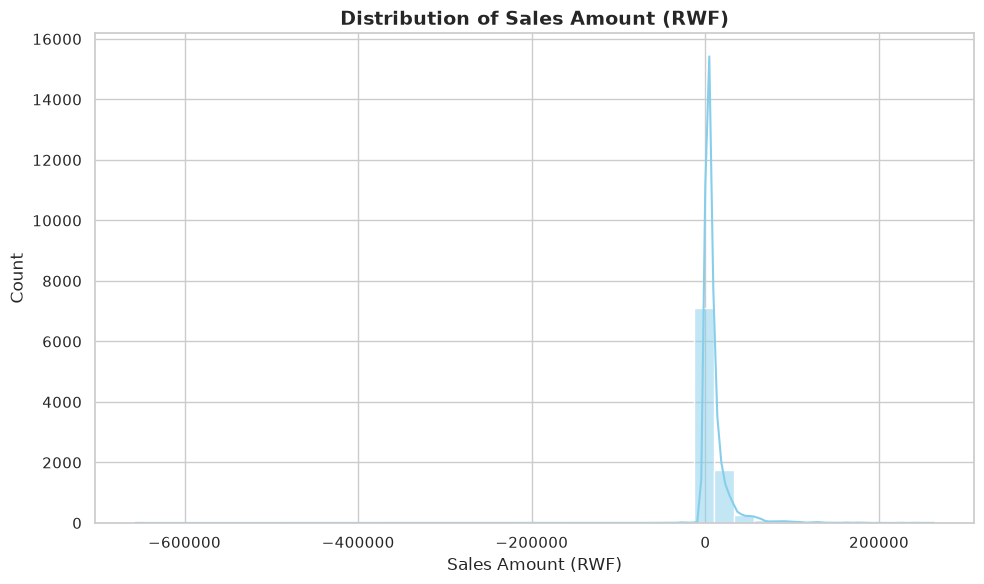

In [49]:
# --- 1. Histogram: Sales Amount ---
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="sales_amount_rwf",
    kde=True,
    bins=40,
    color="skyblue",
)
plt.title(
    "Distribution of Sales Amount (RWF)", fontweight="bold", fontsize=14
)
plt.xlabel("Sales Amount (RWF)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.tight_layout()
plt.show()

### Distribution of Sales Amount (RWF)

Extreme Right Skewness: The vast majority of sales fall into a sharp spike near 0 to 10,000 RWF, representing standard everyday customer retail transactions.

Long Tail to the Right: A thin tail stretches far to the right up to 250,000+ RWF, representing high-value or bulk transactions.

Negative Values on X-Axis: The x-axis extends far into the negative space (down to -650,000 RWF). This compresses the main positive cluster into a narrow vertical line because the plot has to accommodate these severe negative outliers.

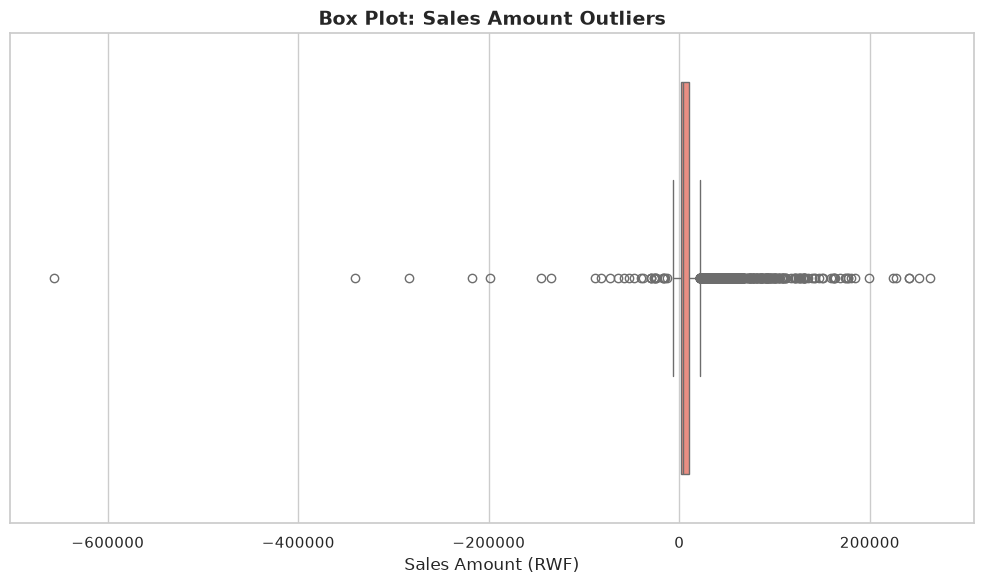

In [50]:
# --- 2. Box Plot: Sales Amount Outliers ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="sales_amount_rwf", color="salmon")
plt.title("Box Plot: Sales Amount Outliers", fontweight="bold", fontsize=14)
plt.xlabel("Sales Amount (RWF)", fontsize=12)
plt.tight_layout()
plt.show()

### Box Plot: Sales Amount Outliers

Main Interquartile Range (IQR): The central box (where $50\%$ of your data lives) is extremely narrow around 2,020 to 9,993 RWF.

Negative Outliers (Left Dots): Individual points stretch far to the left between -200,000 RWF and -656,640 RWF. These represent major customer returns, order cancellations, or account refunds.

Positive Outliers (Right Dots): A dense stream of points extends continuously to the right up to 263,400 RWF. These are unusually high-value bulk purchases sitting far above the upper whisker ($Q3 + 1.5 \times \text{IQR}$). 

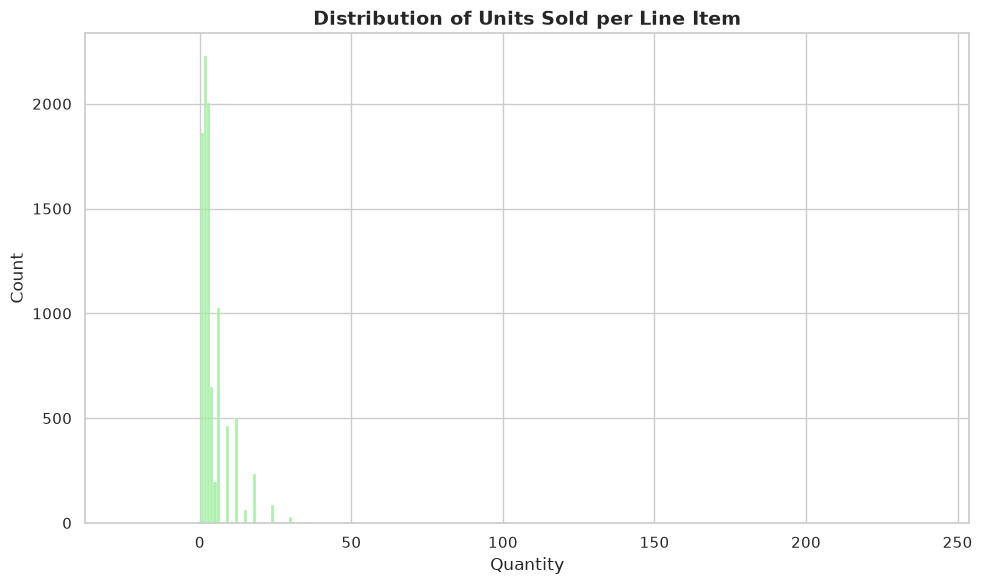

In [51]:
# --- 3. Histogram: Quantity ---
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="quantity", discrete=True, color="lightgreen")
plt.title(
    "Distribution of Units Sold per Line Item", fontweight="bold", fontsize=14
)
plt.xlabel("Quantity", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.tight_layout()
plt.show()

### Distribution of Units Sold per Line Item

Concentration at Low Quantities: Overwhelmingly, most purchases are small retail orders concentrated between 1 and 5 units per line item (peaking around $2,200+$ occurrences for 1–2 items).

Sparse Tail: As quantity increases past 10 units, the frequency drops rapidly. Very few orders lie between 20 and 50 units.

Negative Spike: A small cluster of negative bars appears to the left of zero, representing returned or refunded item quantities.

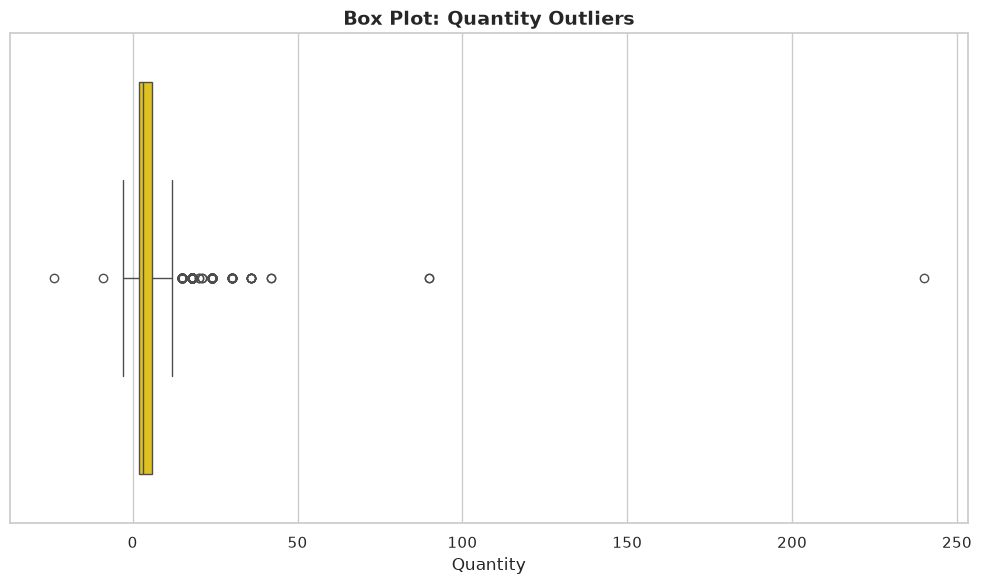

In [52]:
# --- 4. Box Plot: Quantity Outliers ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="quantity", color="gold")
plt.title("Box Plot: Quantity Outliers", fontweight="bold", fontsize=14)
plt.xlabel("Quantity", fontsize=12)
plt.tight_layout()
plt.show()

 ### Box Plot: Quantity Outliers
 
 Normal Range: The solid yellow box ($IQR$) spans tightly between 2 and 6 units, with a median line at 3 units.
 
 Negative Outliers (Left Side): Isolated points appear to the left at -24 units, flagging return transactions.
 
 Extreme Bulk Outliers (Right Side): Clear outlier points extend to the right past 20 units, with a severe extreme outlier at 240 units. This single massive purchase expands the entire x-axis scale.

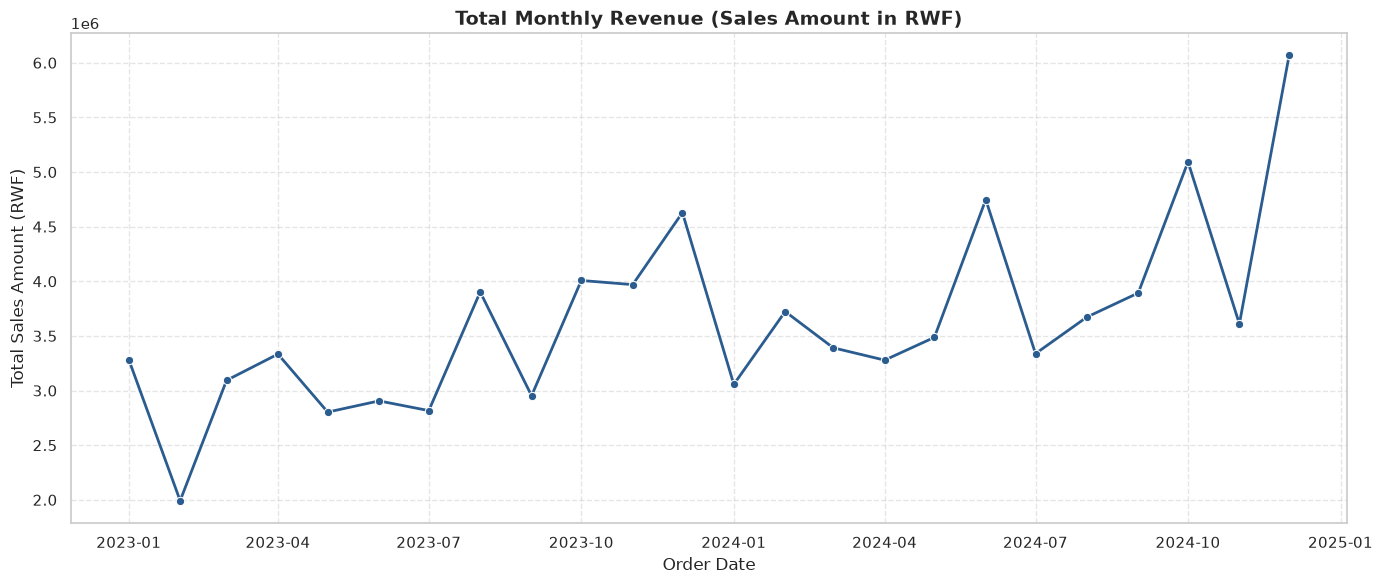

In [36]:
daily_sales = (
    df.groupby("order_date")["sales_amount_rwf"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

df["year_month"] = df["order_date"].dt.to_period("M")
monthly_sales = (
    df.groupby("year_month")["sales_amount_rwf"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)
monthly_sales["year_month"] = monthly_sales["year_month"].dt.to_timestamp()

plt.figure(figsize=(14, 6))

# Change 'monthly_sales' to 'daily_sales' if analyzing daily granularities
sns.lineplot(
    data=monthly_sales,
    x="year_month",
    y="sum",
    marker="o",
    color="#2b5c8f",
    linewidth=2,
)

plt.title(
    "Total Monthly Revenue (Sales Amount in RWF)", fontsize=14, fontweight="bold"
)
plt.xlabel("Order Date", fontsize=12)
plt.ylabel("Total Sales Amount (RWF)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Monthly Revenue Trend Summary

24 consecutive months from January 2023 to December 2024

Overall monthly revenue nearly doubled over two years, growing from ~3.3M RWF in Jan 2023 to a peak of >6.0M RWF in Dec 2024.

Historical Minimum: February 2023 at approximately 2.0M RWF. 

Historical Maximum: December 2024 at over 6.0M RWF.

Notable Mid-Year Spikes: June 2024 (~4.75M RWF) and October 2024 (~5.1M RWF).  

### Category & Product Aggregation & Dual Ranking

Comparing performance across product categories or individual products, aggregate both sales_amount_rwf and quantity, then creating separate rankings to see if the top revenue drivers are also the top volume drivers.

In [42]:
# Aggregate total sales, total quantity, and line item count by Category
cat_summary = (
    df.groupby("category")
    .agg(
        total_sales_rwf=("sales_amount_rwf", "sum"),
        total_quantity=("quantity", "sum"),
        transaction_count=("order_id", "count"),
    )
    .reset_index()
)

# Rank by Total Sales
cat_by_sales = cat_summary.sort_values(
    by="total_sales_rwf", ascending=False
).copy()
cat_by_sales["sales_rank"] = range(1, len(cat_by_sales) + 1)

# Rank separately by Total Quantity
cat_by_qty = cat_summary.sort_values(
    by="total_quantity", ascending=False
).copy()
cat_by_qty["qty_rank"] = range(1, len(cat_by_qty) + 1)

# Combined Ranked Summary
category_rankings = pd.merge(
    cat_by_sales[["sales_rank", "category", "total_sales_rwf"]],
    cat_by_qty[["qty_rank", "category", "total_quantity"]],
    on="category",
)

print("=== CATEGORY RANKINGS (SALES VS QUANTITY) ===")
print(category_rankings)

=== CATEGORY RANKINGS (SALES VS QUANTITY) ===
    sales_rank         category  total_sales_rwf  qty_rank  total_quantity
0            1  Grocery Staples       33531729.0         1            9111
1            2        Beverages       12562913.0         3            6486
2            3     Dairy & Eggs       10807848.0         4            3916
3            4        Household        9768071.0         5            3833
4            5    Personal Care        5906007.0         8            2281
5            6    Fresh Produce        5442371.0         2            8082
6            7           Bakery        4607715.0         6            3742
7            8           Snacks        3700978.0         7            3125
8            9       Beverages          193513.0        11              98
9           10        BEVERAGES         191903.0        10             106
10          11            Snack         124354.0         9             180
11          12           snacks         106286.0      

### Comparing Regions, Customer Segments & Payment Methods

In [40]:
# Function to generate multi-metric summary tables
def analyze_dimension(df, group_col):
    summary = (
        df.groupby(group_col)
        .agg(
            total_sales_rwf=("sales_amount_rwf", "sum"),
            avg_sales_per_item=("sales_amount_rwf", "mean"),
            total_quantity=("quantity", "sum"),
            order_count=("order_id", "nunique"),
        )
        .sort_values(by="total_sales_rwf", ascending=False)
        .reset_index()
    )
    # Calculate percentage share of total revenue
    summary["sales_share_pct"] = (
        summary["total_sales_rwf"] / summary["total_sales_rwf"].sum()
    ) * 100
    return summary


# Generate breakdown reports
region_df = analyze_dimension(df, "store_region")
segment_df = analyze_dimension(df, "customer_segment")
payment_df = analyze_dimension(df, "payment_method")

print("=== REGIONAL BREAKDOWN ===")
print(region_df.to_string(index=False))

print("\n=== CUSTOMER SEGMENT BREAKDOWN ===")
print(segment_df.to_string(index=False))

print("\n=== PAYMENT METHOD BREAKDOWN ===")
print(payment_df.to_string(index=False))

=== REGIONAL BREAKDOWN ===
store_region  total_sales_rwf  avg_sales_per_item  total_quantity  order_count  sales_share_pct
      Kigali       47984156.0         9568.126820           22779         1818        55.122645
     Western       12254280.0         9566.182670            5712          473        14.077320
     Eastern        8099045.0         9494.777257            3941          337         9.303921
    Southern        7005819.0         7979.292711            3386          322         8.048058
    Northern        6747746.0         7976.059102            3120          315         7.751592
      kigali        1211358.0        11876.058824             517          101         1.391569
      KIGALI         959398.0        11155.790698             377           84         1.102125
 Kigali City         749331.0         8325.900000             427           90         0.860807
        West         275213.0        11467.208333             122           24         0.316156
       North 

### Handling Long Product Lists (Top 10 Filtering / Grouping)

If product_name contains dozens or hundreds of items, plotting all of them creates unreadable charts. Filter for the Top 10 products by sales and group remaining products into an 'Other' bucket for total representation.

In [41]:
# Rank products by sales
product_summary = (
    df.groupby("product_name")
    .agg(
        total_sales_rwf=("sales_amount_rwf", "sum"),
        total_quantity=("quantity", "sum"),
    )
    .sort_values(by="total_sales_rwf", ascending=False)
    .reset_index()
)

# Keep Top 10 products
top_10_products = product_summary.head(10)

# Group remaining products into 'Other' for market share calculations
other_sales = product_summary.iloc[10:]["total_sales_rwf"].sum()
other_qty = product_summary.iloc[10:]["total_quantity"].sum()

other_row = pd.DataFrame(
    [
        {
            "product_name": "Other Products Combined",
            "total_sales_rwf": other_sales,
            "total_quantity": other_qty,
        }
    ]
)

product_summary_grouped = pd.concat(
    [top_10_products, other_row], ignore_index=True
)

### Bar Chart Visualizations

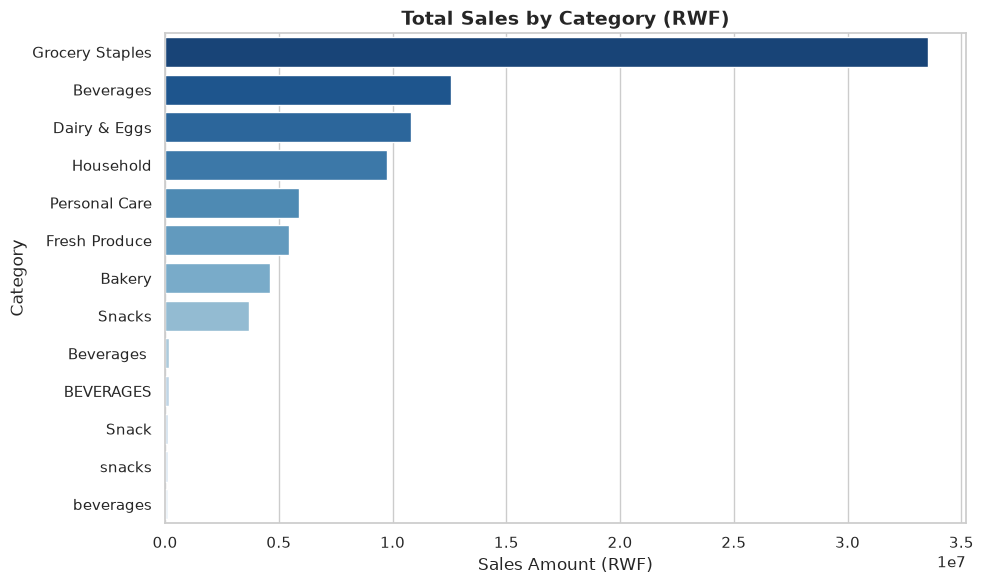

In [45]:
# --- Chart 1: Top Categories by Sales ---
plt.figure(figsize=(10, 6))
sns.barplot(
    data=cat_by_sales,
    x="total_sales_rwf",
    y="category",
    hue="category",
    legend=False,
    palette="Blues_r",
)
plt.title("Total Sales by Category (RWF)", fontweight="bold", fontsize=14)
plt.xlabel("Sales Amount (RWF)", fontsize=12)
plt.ylabel("Category", fontsize=12)
plt.tight_layout()
plt.show()

### Total Sales by Category (RWF)

Primary Revenue Driver: Grocery Staples completely dominates overall sales revenue, generating over $3.3 \times 10^7$ RWF (33.5M RWF)more than double the revenue of the second-highest category.
 
Secondary Performers: Beverages, Dairy & Eggs, and Household follow as steady middle-tier revenue generators ranging between 10M and 13M RWF.
    
Low-Volume/Revenue Categories: Personal Care, Fresh Produce, Bakery, and Snacks contribute smaller amounts to total revenue (under 6M RWF each).
       
Data Cleaning Insight: The small bars at the bottom (Beverages , BEVERAGES, Snack, snacks, beverages) confirm category fragmentation caused by missing text normalization (.str.strip().str.title()). Consolidating these will boost the total figures for Beverages and Snacks.

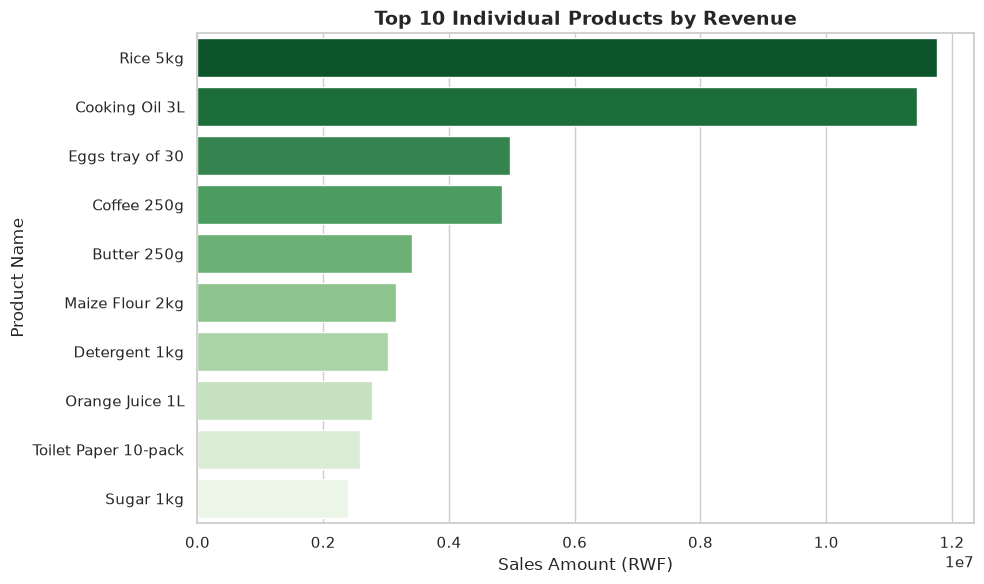

In [46]:
# --- Chart 2: Top 10 Products by Sales ---
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_products,
    x="total_sales_rwf",
    y="product_name",
    hue="product_name",
    legend=False,
    palette="Greens_r",
)
plt.title(
    "Top 10 Individual Products by Revenue", fontweight="bold", fontsize=14
)
plt.xlabel("Sales Amount (RWF)", fontsize=12)
plt.ylabel("Product Name", fontsize=12)
plt.tight_layout()
plt.show()

### Top 10 Individual Products by Revenue

Top Revenue Leaders: Rice 5kg and Cooking Oil 3L are the single highest revenue-generating products, each producing nearly 1.1M to 1.2M RWF in sales.

Mid-Tier Movers: Eggs tray of 30 and Coffee 250g occupy the 3rd and 4th spots, generating around 500,000 RWF each.

Core Household Pantry Items: The remaining top products Butter 250g, Maize Flour 2kg, Detergent 1kg, Orange Juice 1L, Toilet Paper 10-pack, and Sugar 1kg each generate steady revenue between 250,000 RWF and 350,000 RWF.

Pareto Distribution Insight: Essential kitchen staples account for the vast majority of total top product revenue.

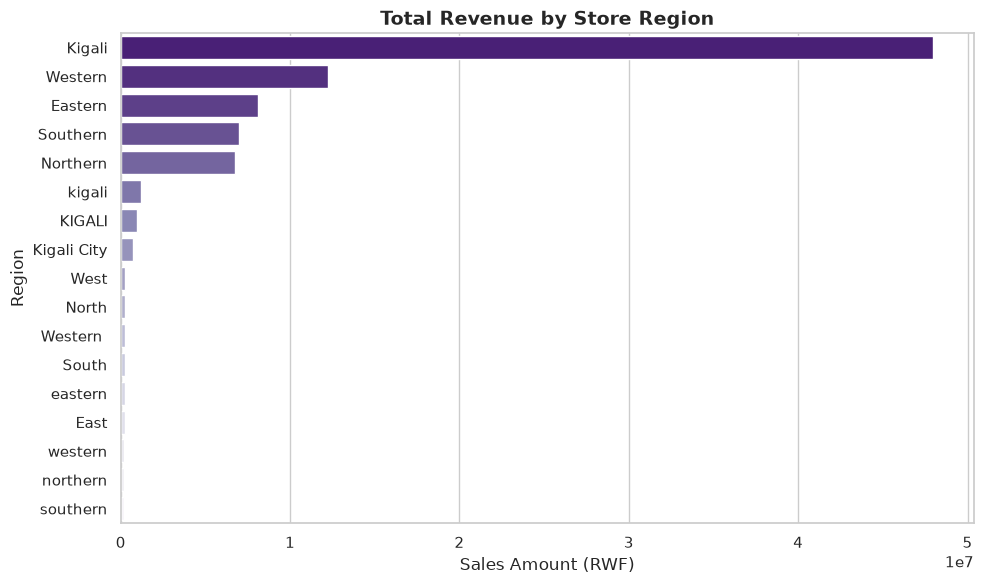

In [47]:
# --- Chart 3: Regional Revenue Comparison ---
plt.figure(figsize=(10, 6))
sns.barplot(
    data=region_df,
    x="total_sales_rwf",
    y="store_region",
    hue="store_region",
    legend=False,
    palette="Purples_r",
)
plt.title("Total Revenue by Store Region", fontweight="bold", fontsize=14)
plt.xlabel("Sales Amount (RWF)", fontsize=12)
plt.ylabel("Region", fontsize=12)
plt.tight_layout()
plt.show()

### Total Revenue by Store Region

Extreme Regional Concentration: Kigali is the dominant sales region by a massive margin, accounting for nearly $4.8 \times 10^7$ RWF (48M RWF) in total sales.

Secondary Regional Markets: The Western Region is the second largest market (around 1.2M RWF), followed by Eastern, Southern, and Northern regions (each bringing in under 1M RWF).

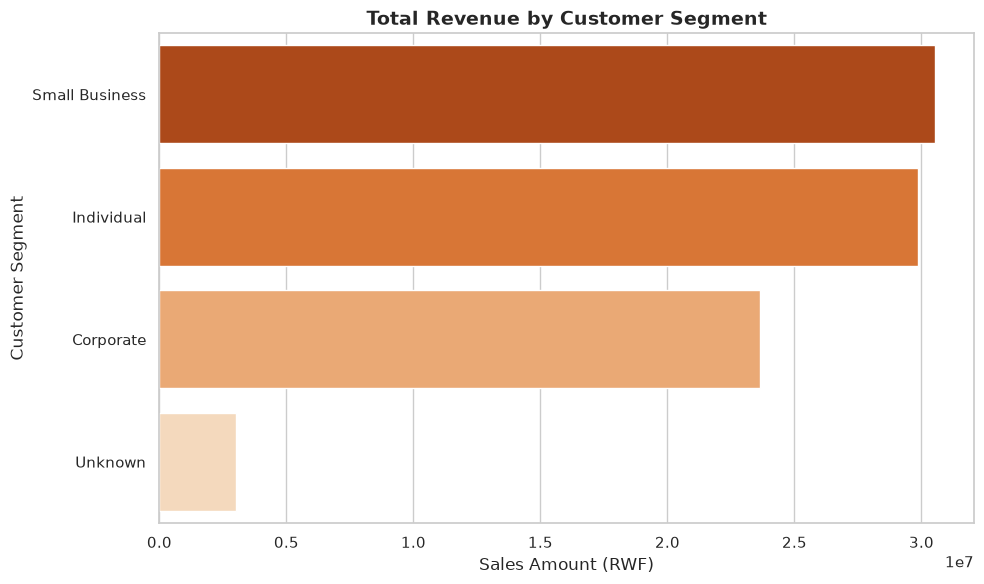

In [48]:
# --- Chart 4: Customer Segment Revenue Comparison ---
plt.figure(figsize=(10, 6))
sns.barplot(
    data=segment_df,
    x="total_sales_rwf",
    y="customer_segment",
    hue="customer_segment",
    legend=False,
    palette="Oranges_r",
)
plt.title("Total Revenue by Customer Segment", fontweight="bold", fontsize=14)
plt.xlabel("Sales Amount (RWF)", fontsize=12)
plt.ylabel("Customer Segment", fontsize=12)
plt.tight_layout()
plt.show()

### Total Revenue by Customer Segment

Top Customer Segments: Small Business and Individual customers drive the vast majority of sales revenue, each contributing approximately $3.0 \times 10^7$ RWF (30M RWF).

Corporate Accounts: Corporate clients form a solid third segment, bringing in roughly 2.3M RWF.

Missing Data Impact: The Unknown segment accounts for a small portion (under 0.3M RWF), representing transactions where customer segment information was unrecorded.

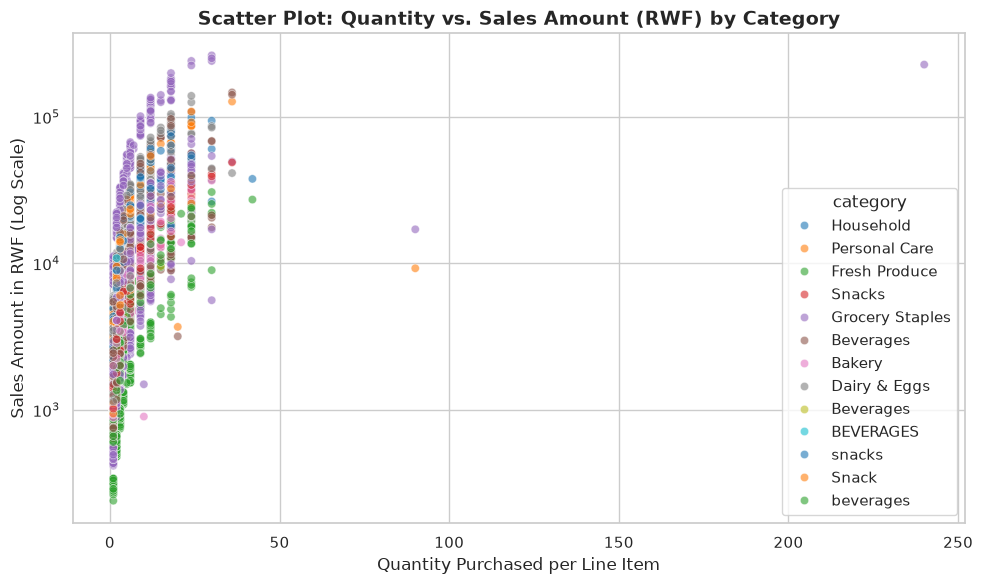

In [56]:
# Isolate positive transactions to inspect core relationship
positive_sales = df[df["quantity"] > 0].copy()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=positive_sales,
    x="quantity",
    y="sales_amount_rwf",
    hue="category",
    alpha=0.6,
    palette="tab10",
)
plt.yscale("log")  # Log scale handles extreme spread across price points
plt.title(
    "Scatter Plot: Quantity vs. Sales Amount (RWF) by Category",
    fontweight="bold",
    fontsize=14,
)
plt.xlabel("Quantity Purchased per Line Item", fontsize=12)
plt.ylabel("Sales Amount in RWF (Log Scale)", fontsize=12)
plt.tight_layout()
plt.show()

#### General Positive Correlation: For the vast majority of items (quantities between 1 and 35), higher quantities directly correlate with higher sales amounts.

## TRUE ORDER-LEVEL ANALYSIS (AOV)

In [ ]:
# Step A: Aggregate to true Order Level
order_level_df = (
    df.groupby("order_id")
    .agg(
        total_order_value=(
            "sales_amount_rwf",
            "sum",
        ),  
        items_in_order=("line_number", "count"),
        order_date=("order_date", "first"),
        customer_segment=("customer_segment", "first"),
        store_region=("store_region", "first"),
    )
    .reset_index()
)

# Step B: Compare Average Order Value (AOV) across segments without double-counting
aov_by_segment = (
    order_level_df.groupby("customer_segment")
    .agg(
        mean_aov=("total_order_value", "mean"),
        median_aov=("total_order_value", "median"),
        total_orders=("order_id", "count"),
    )
    .sort_values(by="mean_aov", ascending=False)
    .reset_index()
)

print("=== TRUE ORDER-LEVEL ANALYSIS (AOV) ===")
print(aov_by_segment)

=== TRUE ORDER-LEVEL ANALYSIS (AOV) ===
  customer_segment      mean_aov  median_aov  total_orders
0        Corporate  82222.875000     61182.0           288
1   Small Business  42647.802778     30813.0           720
2          Unknown  27103.989583     13409.0            96
3       Individual  13689.079235     10808.0          2196


### Order-Level Analysis (AOV) Breakdown
- Corporate Segment Dominance: Corporate clients yield the highest Average Order Value with a mean AOV of 82,222.88 RWF and a median AOV of 61,182.00 RWF across 288 orders. Their purchases represent large bulk transactions.

- Small Business Volume: Small Business accounts represent the largest overall order volume (720 orders) with a mean AOV of 42,647.80 RWF (median of 30,813.00 RWF). They serve as the primary steady commercial buyer base.

- Individual Customer Pattern: Individual consumers place 2,196 orders (the second-highest order count), but have the lowest average cart size with a mean AOV of 13,689.08 RWF and a median AOV of 10,808.00 RWF.

- Skewness Across Segments: Across all segments, the mean AOV is consistently higher than the median AOV (e.g., Corporate mean 82.2k vs. median 61.2k), confirming that every customer segment contains a small set of unusually large transactions pulling the average upward.

### Category Price Efficiency

In [59]:
# Identify categories with high volume but low sales, or vice versa
category_efficiency = (
    df.groupby("category")
    .agg(
        total_sales=("sales_amount_rwf", "sum"),
        total_quantity=("quantity", "sum"),
        transaction_count=("order_id", "count"),
    )
    .reset_index()
)

category_efficiency["avg_unit_price"] = (
    category_efficiency["total_sales"] / category_efficiency["total_quantity"]
)
category_efficiency["sales_per_trans"] = (
    category_efficiency["total_sales"]
    / category_efficiency["transaction_count"]
)

print(
    category_efficiency.sort_values(by="avg_unit_price", ascending=False).to_string(
        index=False
    )
)

       category  total_sales  total_quantity  transaction_count  avg_unit_price  sales_per_trans
Grocery Staples   33531729.0            9111               1995     3680.356602     16807.884211
      beverages     106119.0              34                 13     3121.147059      8163.000000
   Dairy & Eggs   10807848.0            3916                912     2759.920327     11850.710526
  Personal Care    5906007.0            2281                511     2589.218325     11557.743640
      Household    9768071.0            3833                862     2548.414036     11331.868910
     Beverages      193513.0              98                 25     1974.622449      7740.520000
      Beverages   12562913.0            6486               1539     1936.927690      8163.036387
      BEVERAGES     191903.0             106                 24     1810.405660      7995.958333
         Bakery    4607715.0            3742                842     1231.350882      5472.345606
         Snacks    3700978.0  

### Category Price Efficiency & Unit Price Discrepancies

Highest Unit Price Categories:

Grocery Staples: Leads in average unit price (3,680.36 RWF/unit) and yields the highest average revenue per transaction (16,807.88 RWF/trans).

Dairy & Eggs: Averages 2,759.92 RWF/unit with 11,850.71 RWF/trans.

Personal Care & Household: Average ~2,550 to 2,589 RWF/unit with transactions averaging ~11,300 to 11,550 RWF.

Lowest Unit Price Categories (High Volume Drivers):

Fresh Produce: Has the lowest average unit price in the dataset (673.39 RWF/unit) and lowest sales per transaction (2,864.41 RWF/trans). Despite generating over 8,000 units in volume, its low price point limits total revenue.

Bakery & Snacks: Low unit prices (1,184 to 1,231 RWF/unit) result in lower transaction values (~5,200 to 5,470 RWF).

Uncleaned Category Splitting:

The raw table re-confirms text formatting gaps: Beverages appears 4 times (beverages, Beverages, BEVERAGES, Beverages ), and Snacks appears 3 times (Snacks, snacks, Snack).